# Benchmark - analysis
All the games played, old and new, in one table (one row per game), and the graphs of the comparison between models and modes.
Run it locally: copy the results folder from Google Drive (`MyDrive/LLMs-Play-Textual-Games/Benchmark/results`) into `Code/Benchmark/results_new`.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

sys.path.insert(0, os.getcwd())
from records import LEGACY_RESULTS, load_table

folders = [LEGACY_RESULTS, "results_new"] # the old experiments, the games played by run.py
table = load_table(*[folder for folder in folders if os.path.isdir(folder)])
print(f"{len(table)} games")
table.groupby(["model", "prompt", "game", "mode"]).size().unstack("mode").fillna(0).astype(int)

7741 games


mode                                        0   e1  er10  er4  lr4  r10   r4
model           prompt  game                                                
Qwen/Qwen3-1.7B CoT     cooking            50   50     0   50   50    0   50
Qwen/Qwen3-4B   CoT     coin_collector      0  140     0    0    0  280  280
                        cooking             0   90     1  100   90  180  180
                        treasure_hunter     0  270     0    0    0  540  540
                default coin_collector    500  140     0    0    0  280  280
                        cooking           450   90     0    0    0  180  180
                        treasure_hunter  1350  270     0    0    0  540  540

# Selection
The games compared: every model and mode on the same games (same levels and seeds), so that the averages are comparable.
`models` is the order of the graphs (by size); the models without games are left out.
Tokens: the old Qwen3-4B r4-think games have logs only for seeds 11-20, so the tokens are averaged on `token_seeds`.

In [2]:
prompt = "CoT"
game = "cooking"
levels = [1, 3, 5, 7, 9]
seeds = range(1, 11)
token_seeds = range(1, 21)
modes = ["0", "e1", "r4", "er4", "lr4"]
models = ["Qwen/Qwen3-0.6B", "Qwen/Qwen3-1.7B", "Qwen/Qwen3-4B", "Qwen/Qwen3-8B-FP8", "Qwen/Qwen3-14B-AWQ",
          "HuggingFaceTB/SmolLM3-3B", "deepseek-ai/DeepSeek-R1-Distill-Llama-8B"]

selected = table[(table.prompt == prompt) & (table.game == game) & table.level.isin(levels)]
scores = selected[selected.seed.isin(seeds)]
tokens = selected[selected.seed.isin(token_seeds) & selected.tokens_generated.notna()]
models = [model for model in models if model in set(scores.model)]
modes = [mode for mode in modes if mode in set(scores["mode"])]
short = {model: model.split("/")[-1] for model in models}

def mean_ci(values):
    """Mean and 90% bootstrap confidence interval (the mean itself when there are less than 2 values)."""
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return values.mean() if len(values) else np.nan, np.nan, np.nan
    ci = bootstrap((values,), np.mean, method="basic", n_resamples=1000, confidence_level=0.9).confidence_interval
    return values.mean(), ci.low, ci.high

summary = []
for model in models:
    for mode in modes:
        s = scores[(scores.model == model) & (scores["mode"] == mode)]
        t = tokens[(tokens.model == model) & (tokens["mode"] == mode)]
        if len(s) == 0:
            continue
        summary.append(dict(model=short[model], mode=mode, games=len(s), score=s.norm_score.mean(),
                            ktokens_per_game=t.tokens_generated.mean() / 1000, token_games=len(t),
                            loops=s.loop_stopped.fillna(False).sum()))
import pandas as pd
pd.DataFrame(summary).set_index(["model", "mode"]).round(2)

games  score  ktokens_per_game  token_games  loops
model      mode                                                    
Qwen3-1.7B 0        50   0.02              1.62           50     24
           e1       50   0.21             42.93           50      8
           r4       50   0.05              5.07           50     13
           er4      50   0.04              2.43           50      7
           lr4      50   0.06              2.97           50      3
Qwen3-4B   e1       50   0.47             61.65           50      0
           r4       50   0.24              7.03           47      0
           er4      50   0.35             10.65           58     12
           lr4      50   0.42             11.68           42      8

# Graphs
Same colors, line styles and markers of the graphs of the experiments 6e/7e/8 (each mode has its own marker and line style, so the modes are distinguishable without colors).
Shaded areas and error bars: 90% bootstrap confidence intervals over the games.

In [3]:
styles = {"0":   dict(color="#e34948", linestyle=":",  marker="v"),
          "e1":  dict(color="#008300", linestyle="--", marker="s"),
          "r4":  dict(color="#2a78d6", linestyle="-.", marker="o"),
          "er4": dict(color="#4a3aa7", linestyle="-",  marker="D"),
          "lr4": dict(color="#c86a00", linestyle="-",  marker="^")}
labels = {"0": "0-think (never)", "e1": "e1-think (every turn)", "r4": "r4-think (all reasonings kept)",
          "er4": "er4-think (no reasoning kept)", "lr4": "lr4-think (last reasoning kept)"}
os.makedirs("graphs", exist_ok=True)

def style_axis(ax, title, ylabel):
    ax.set_title(title, weight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

## Score and cost per model
Average over all the selected games of each model (levels and seeds together). Two separate charts, one per measure.

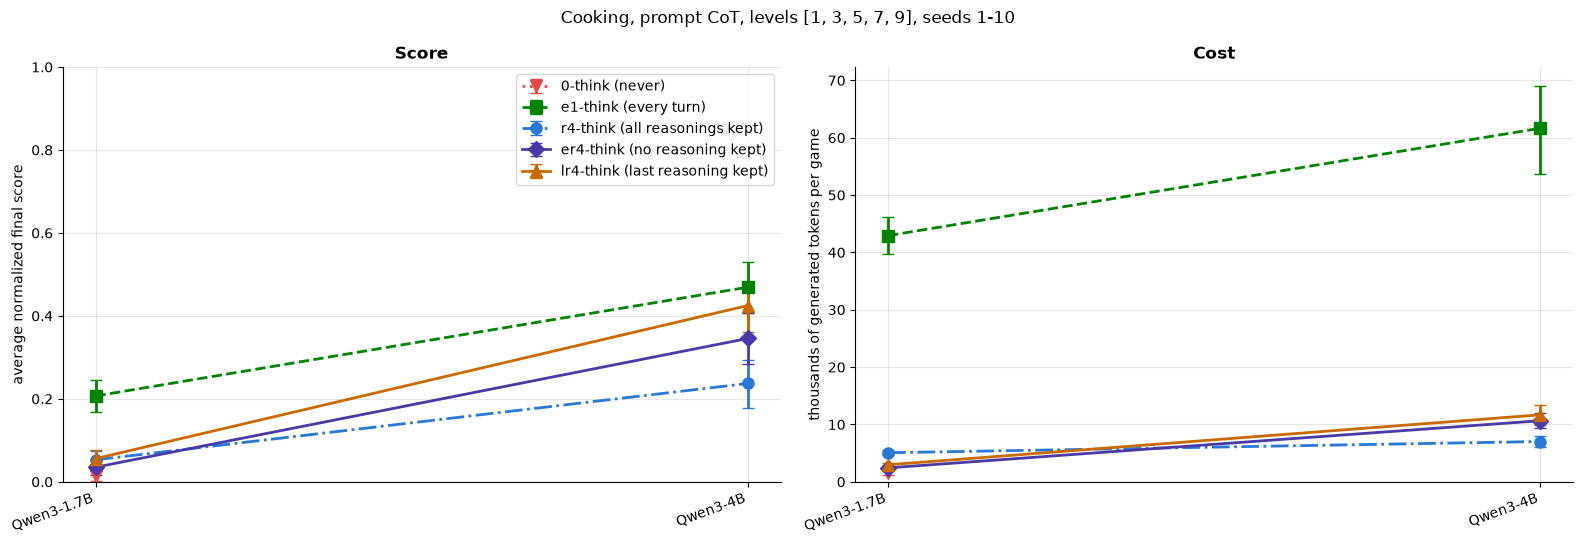

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(models))
for column, (data, value, ylabel, title) in enumerate([
        (scores, lambda d: d.norm_score, "average normalized final score", "Score"),
        (tokens, lambda d: d.tokens_generated / 1000, "thousands of generated tokens per game", "Cost")]):
    ax = axes[column]
    for mode in modes:
        points = [mean_ci(value(data[(data.model == model) & (data["mode"] == mode)])) for model in models]
        y = np.array([p[0] for p in points])
        low = np.array([p[1] for p in points])
        high = np.array([p[2] for p in points])
        if np.isnan(y).all():
            continue
        ax.errorbar(x, y, yerr=[np.nan_to_num(y - low), np.nan_to_num(high - y)], capsize=4, linewidth=2,
                    markersize=8, label=labels[mode], **styles[mode])
    ax.set_xticks(x, [short[model] for model in models], rotation=20, ha="right")
    style_axis(ax, title, ylabel)
    ax.set_ylim(0, 1 if column == 0 else None)
    if column == 1:
        ax.set_ylim(bottom=0)
axes[0].legend()
fig.suptitle(f"{game.capitalize()}, prompt {prompt}, levels {levels}, seeds {seeds[0]}-{seeds[-1]}")
fig.tight_layout()
fig.savefig(f"graphs/models_{game}_{prompt}.pdf", bbox_inches="tight")
plt.show()

## Score against cost
One point per model and mode: higher is better, further left is cheaper. The label is the model.

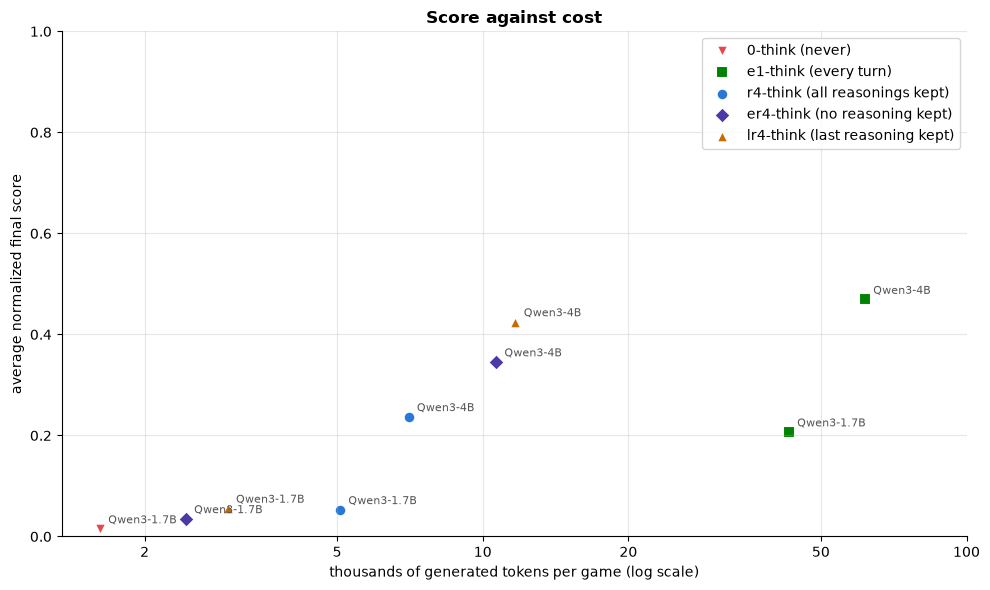

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
for mode in modes:
    labelled = False
    for model in models:
        s = scores[(scores.model == model) & (scores["mode"] == mode)]
        t = tokens[(tokens.model == model) & (tokens["mode"] == mode)]
        if len(s) == 0 or len(t) == 0:
            continue
        ax.scatter(t.tokens_generated.mean() / 1000, s.norm_score.mean(), s=70, color=styles[mode]["color"],
                   marker=styles[mode]["marker"], edgecolor="white", linewidth=1.5,
                   label=None if labelled else labels[mode])
        labelled = True
        ax.annotate(short[model], (t.tokens_generated.mean() / 1000, s.norm_score.mean()),
                    textcoords="offset points", xytext=(6, 4), fontsize=8, color="#555555")
ax.set_xscale("log")
ax.set_xticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
ax.minorticks_off()
ax.set_xlabel("thousands of generated tokens per game (log scale)")
style_axis(ax, "Score against cost", "average normalized final score")
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(f"graphs/score_vs_cost_{game}_{prompt}.pdf", bbox_inches="tight")
plt.show()

## Score per level
One panel per model, as in the graphs of the old experiments.

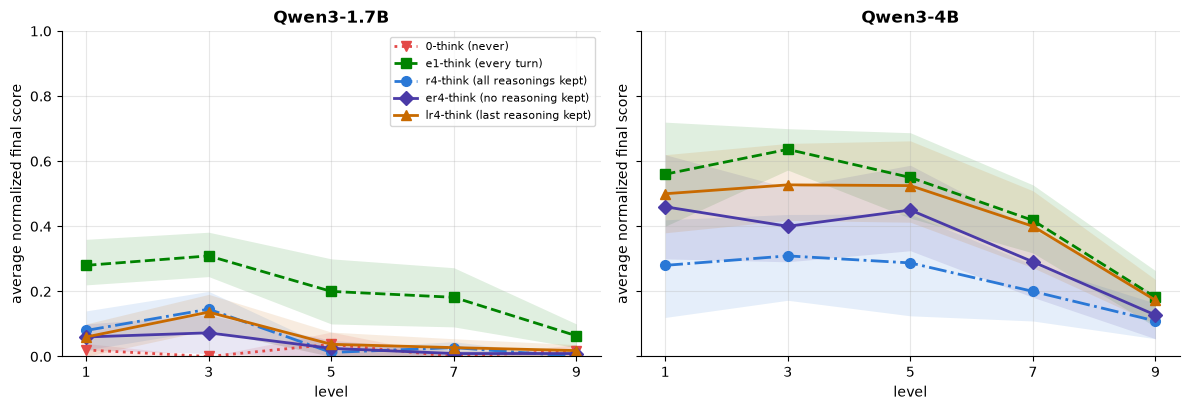

In [6]:
columns = min(3, len(models))
rows = int(np.ceil(len(models) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 4.2 * rows), squeeze=False, sharey=True)
for ax, model in zip(axes.flat, models):
    for mode in modes:
        points = [(level, *mean_ci(scores[(scores.model == model) & (scores["mode"] == mode) & (scores.level == level)].norm_score))
                  for level in levels]
        points = [p for p in points if not np.isnan(p[1])]
        if not points:
            continue
        lx, y, low, high = (np.array(v) for v in zip(*points))
        ax.fill_between(lx, np.clip(np.where(np.isnan(low), y, low), 0, 1), np.clip(np.where(np.isnan(high), y, high), 0, 1),
                        color=styles[mode]["color"], alpha=0.12, linewidth=0)
        ax.plot(lx, y, label=labels[mode], linewidth=2, markersize=7, **styles[mode])
    style_axis(ax, short[model], "average normalized final score")
    ax.set_xlabel("level")
    ax.set_xticks(levels)
    ax.set_ylim(0, 1)
for ax in list(axes.flat)[len(models):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"graphs/levels_{game}_{prompt}.pdf", bbox_inches="tight")
plt.show()